# Pathfinder: a small routing problem as a QUBO

Work through a routing problem from start to finish: describe a network, formulate
the constraints, generate a QUBO with **MQT ProblemSolver's Pathfinder**, solve it,
and interpret the resulting route.

By the end, you should be able to:

- Explain how one-hot binary variables represent a route.
- Distinguish travel cost from constraint penalties.
- Build a QUBO and check its energies against an independent formulation.
- Decode solver results and assess feasibility and optimality.

All data are included below. The exact solver and simulated annealing run on your
computer; no account, API key or quantum device is needed. After installation,
the example runs without downloading any datasets.

This introduction models **one journey**. Your team's mobility challenge extends
these ideas to competing journeys, limited capacity and protected priority claims.


## Getting started

Use **Python 3.12** and the supplied `requirements.txt`. See `START_HERE.txt` for
installation instructions. This example uses **MQT ProblemSolver 0.5.0** and
**dimod 0.12.22**; the supplied requirements pin the tested package versions.

Once installed, select the environment's Python kernel and choose
**Kernel → Restart Kernel and Run All Cells**. Saved outputs illustrate a completed
run; running the cells produces your own results. Read each section before moving
on, and make a copy before attempting the exercises.

The optional installation cell below is only needed if the packages have not
already been installed in the active kernel. Restart the kernel after installation.


In [1]:
# Optional: uncomment only if packages are not installed, then restart the kernel.
# %pip install -r requirements.txt


In [2]:
import itertools
import platform
import random
import time
from importlib.metadata import version

import dimod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dimod import SimulatedAnnealingSampler
from IPython.display import display

import mqt.problemsolver.qubo_tools.pathfinder as pf

print("Python:", platform.python_version())
for package in ["mqt.problemsolver", "dimod", "numpy", "pandas", "matplotlib", "sympy"]:
    print(f"{package}: {version(package)}")
if version("mqt.problemsolver") != "0.5.0":
    print("Note: this notebook targets MQT ProblemSolver 0.5.0; check API differences.")


Python: 3.12.15
mqt.problemsolver: 0.5.0
dimod: 0.12.22
numpy: 2.5.4
pandas: 2.3.3
matplotlib: 3.11.2
sympy: 1.14.0


## 1. The problem

A shuttle travels from **Depot (1)** to **Station (5)** through exactly one
intermediate stop: **North (2)**, **Centre (3)** or **South (4)**.
Each directed edge has a fixed travel time in minutes. Choose the fastest route.

Requirements:

- Start at vertex 1 and finish at vertex 5.
- Visit exactly **three vertices**, including the start and finish: two edges.
- Use only the directed edges in the network.

The fixed number of stops is part of this exercise, not a general restriction of
Pathfinder. Travel times are illustrative constants; there is no departure time,
timetable, congestion or waiting in this model. Arrow direction matters.

**Before running the solvers:** calculate the three route times by hand.


In [3]:
N_VERTICES = 5
N_POSITIONS = 3
START, END = 1, 5
NAMES = {1: "Depot", 2: "North", 3: "Centre", 4: "South", 5: "Station"}

# (from_vertex, to_vertex, travel_minutes); vertex IDs are 1-based in Pathfinder.
EDGES = [(1, 2, 2), (2, 5, 4), (1, 3, 4), (3, 5, 1), (1, 4, 1), (4, 5, 6)]
WEIGHTS = {(u, v): float(w) for u, v, w in EDGES}
assert len(WEIGHTS) == len(EDGES), "Use at most one edge per ordered pair."
assert all(1 <= u <= N_VERTICES and 1 <= v <= N_VERTICES and w > 0 for u, v, w in EDGES)

# Zero means no edge in Pathfinder; it is not a free journey.
A = np.zeros((N_VERTICES, N_VERTICES))
for u, v, weight in EDGES:
    A[u - 1, v - 1] = weight

graph = pf.Graph(N_VERTICES, EDGES)
display(pd.DataFrame(EDGES, columns=["from", "to", "minutes"]))


,from,to,minutes
0,1,2,2
1,2,5,4
2,1,3,4
3,3,5,1
4,1,4,1
5,4,5,6


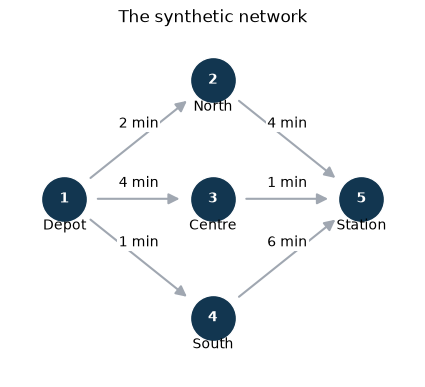

In [4]:
POSITIONS = {1: (0, 0), 2: (1.5, 1.2), 3: (1.5, 0), 4: (1.5, -1.2), 5: (3, 0)}

def plot_route(route=None, title="The synthetic network"):
    selected = set(zip(route, route[1:])) if route is not None else set()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for u, v, minutes in EDGES:
        x1, y1 = POSITIONS[u]
        x2, y2 = POSITIONS[v]
        chosen = (u, v) in selected
        colour = "#00796b" if chosen else "#a0a7b1"
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="-|>", color=colour, lw=3 if chosen else 1.5,
                                    shrinkA=24, shrinkB=24, mutation_scale=16))
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.12, f"{minutes:g} min",
                ha="center", fontsize=10, bbox=dict(facecolor="white", edgecolor="none", pad=1))
    for vertex, (x, y) in POSITIONS.items():
        ax.scatter(x, y, s=1100, color="#123650", edgecolor="white", zorder=3)
        ax.text(x, y, str(vertex), color="white", ha="center", va="center", weight="bold", zorder=4)
        ax.text(x, y - 0.31, NAMES[vertex], ha="center", fontsize=10)
    ax.set(xlim=(-0.55, 3.55), ylim=(-1.8, 1.7), title=title)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.show()

plot_route()


## 2. Mathematical formulation

Let $x_{i,v}=1$ when vertex $v$ occupies position $i$ of the route, and 0 otherwise.
There are $3\times5=15$ binary variables. A valid route has exactly one selected
vertex per position. For example, $1\to3\to5$ is encoded as

```text
position 1: 1 0 0 0 0
position 2: 0 0 1 0 0
position 3: 0 0 0 0 1
```

The objective is the sum of travel times along consecutive selected vertices:

$$f(x)=\sum_{i=1}^{2}\sum_{(u,v)\in E} w_{uv}x_{i,u}x_{i+1,v}.$$

Arbitrary bitstrings are **not all feasible routes**.
The all-zero bitstring even has travel cost zero! We need penalties for missing
or multiple vertices, wrong endpoints and nonexistent edges.

Write $s_i=\sum_v x_{i,v}$. For the constraints used below, Pathfinder 0.5.0 generates

$$H(x)=f(x)+P\left[C_{\mathrm{positions}}+C_{\mathrm{endpoints}}+
C_{\mathrm{edges}}+C_{\mathrm{encoding}}\right],$$

where

$$C_{\mathrm{positions}}=\sum_i(1-s_i)^2,\qquad
C_{\mathrm{endpoints}}=(1-x_{1,1})^2+(1-x_{3,5})^2,$$

$$C_{\mathrm{edges}}=\sum_{i=1}^{2}\sum_{(u,v)\notin E}x_{i,u}x_{i+1,v},\qquad
C_{\mathrm{encoding}}=\sum_i s_i(s_i-1).$$

The last term is Pathfinder's additional one-hot validity penalty. It overlaps
with the position penalty for multiple selections; including it here makes our
independent check match the generated model exactly. All four penalties are
nonnegative on binary assignments and vanish on feasible routes.

We choose $P=2\max(w)+1=13$. A feasible two-edge route costs at most 12 minutes,
whereas any infeasible assignment pays at least 13 and has nonnegative travel cost.
Since a feasible route exists, a **global minimiser** must be feasible. A heuristic
can still return an infeasible sample, so we check every result.


## 3. Generate the QUBO with Pathfinder

`max_path_length` counts **vertex positions**, not travel minutes. It is a maximum;
we explicitly require a vertex in every position to obtain exactly three here.
`loops=False` means the model does not require a closing edge from the last
position back to the first; this is an open route.

`PathIsValid` checks adjacency and encoding validity. On its own it does not require
every slot to be occupied. `PathPositionIs` supplies that requirement. We use a fixed
last position for the destination because this exercise fixes the number of stops.
For a variable-length route, `PathEndsAt` is the relevant endpoint constraint.


In [5]:
PENALTY = (N_POSITIONS - 1) * max(WEIGHTS.values()) + 1

def build_pathfinder(network, penalty):
    settings = pf.PathFindingQuboGeneratorSettings(
        encoding_type=pf.EncodingType.ONE_HOT,
        n_paths=1,
        max_path_length=N_POSITIONS,
        loops=False,
    )
    generator = pf.PathFindingQuboGenerator(
        objective_function=pf.MinimizePathLength(path_ids=[1]),
        graph=network,
        settings=settings,
    )
    generator.add_constraint(pf.PathIsValid(path_ids=[1]), weight=penalty)
    for position in range(1, N_POSITIONS + 1):
        generator.add_constraint(
            pf.PathPositionIs(position=position, vertex_ids=network.all_vertices, path=1),
            weight=penalty,
        )
    generator.add_constraint(pf.PathStartsAt(vertex_ids=[START], path=1), weight=penalty)
    generator.add_constraint(
        pf.PathPositionIs(position=N_POSITIONS, vertex_ids=[END], path=1), weight=penalty
    )
    return generator

generator = build_pathfinder(graph, PENALTY)
Q = np.asarray(generator.construct_qubo_matrix(), dtype=float)
n_encoding = generator.get_encoding_variable_count()
assert Q.shape == (N_VERTICES * N_POSITIONS, N_VERTICES * N_POSITIONS), "Unexpected auxiliary variables."
assert n_encoding == len(Q)
assert np.allclose(Q, np.triu(Q)), "Expected the upper-triangular MQT matrix convention."

# MQT's matrix omits the constant. At x=0, all variable terms vanish.
offset = float(generator.get_cost([0] * n_encoding))
qubo = {(i, j): float(Q[i, j]) for i in range(len(Q)) for j in range(i, len(Q)) if Q[i, j] != 0}
bqm = dimod.BinaryQuadraticModel.from_qubo(qubo, offset=offset)
for i in range(len(Q)):
    bqm.add_variable(i, 0.0)  # Preserve any variable whose net coefficient happens to be zero.

print(f"Variables: {bqm.num_variables}; penalty: {PENALTY:g}; constant offset: {offset:g}")
print("Energy convention: H(x) = x.T @ Q @ x + offset; do not double the off-diagonal entries.")


Variables: 15; penalty: 13; constant offset: 65
Energy convention: H(x) = x.T @ Q @ x + offset; do not double the off-diagonal entries.


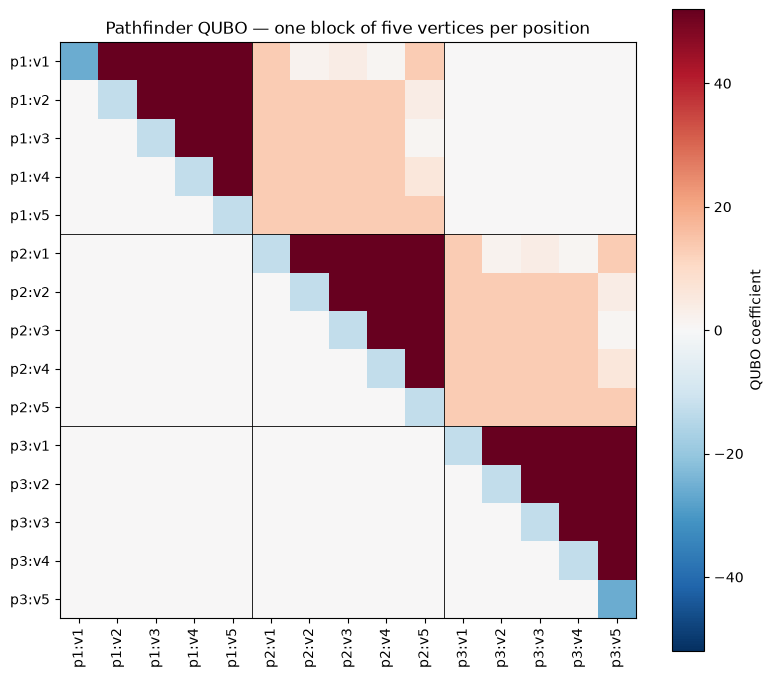

In [6]:
labels = [f"p{i}:v{v}" for i in range(1, N_POSITIONS + 1) for v in range(1, N_VERTICES + 1)]
fig, ax = plt.subplots(figsize=(8, 7))
limit = max(1.0, float(np.max(np.abs(Q))))
im = ax.imshow(Q, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set_xticks(range(len(Q)), labels, rotation=90)
ax.set_yticks(range(len(Q)), labels)
for boundary in range(N_VERTICES, len(Q), N_VERTICES):
    ax.axhline(boundary - 0.5, color="black", lw=0.6)
    ax.axvline(boundary - 0.5, color="black", lw=0.6)
ax.set_title("Pathfinder QUBO — one block of five vertices per position")
fig.colorbar(im, ax=ax, label="QUBO coefficient")
plt.tight_layout()
plt.show()


## 4. Check the model independently

First enumerate routes directly from the original graph, without a QUBO. Then
enumerate all $2^{15}=32,768$ bitstrings with `ExactSolver` and check their energies
against the formula in section 2. This checks invalid assignments too.

Do not trust decoding alone: a decoder can turn malformed one-hot bits into a list
of vertices. We inspect each position before accepting its route.


In [7]:
def check_route(route):
    if len(route) != N_POSITIONS or route[0] != START or route[-1] != END:
        return False, np.nan
    edges = list(zip(route, route[1:]))
    if not all(edge in WEIGHTS for edge in edges):
        return False, np.nan
    return True, sum(WEIGHTS[edge] for edge in edges)

reference_routes = []
for middle in itertools.product(range(1, N_VERTICES + 1), repeat=N_POSITIONS - 2):
    route = [START, *middle, END]
    feasible, minutes = check_route(route)
    if feasible:
        reference_routes.append(dict(route=route, minutes=minutes))
reference = pd.DataFrame(reference_routes).sort_values("minutes").reset_index(drop=True)
assert not reference.empty, "This instance has no feasible route."
reference_optimum = float(reference.minutes.min())
display(reference)

def inspect_bits(bits):
    bits = np.asarray(bits, dtype=int)
    if len(bits) != N_VERTICES * N_POSITIONS or not np.isin(bits, [0, 1]).all():
        return dict(feasible=False, route=None, minutes=np.nan, reason="invalid bit array")
    slots = bits.reshape(N_POSITIONS, N_VERTICES)
    if not np.all(slots.sum(axis=1) == 1):
        return dict(feasible=False, route=None, minutes=np.nan, reason="not one vertex per position")
    route = (slots.argmax(axis=1) + 1).tolist()
    feasible, minutes = check_route(route)
    return dict(feasible=feasible, route=route, minutes=minutes,
                reason="OK" if feasible else "wrong endpoint or missing directed edge")

def independent_energies(samples, penalty=PENALTY):
    slots = np.asarray(samples, dtype=int).reshape(-1, N_POSITIONS, N_VERTICES)
    counts = slots.sum(axis=2)
    travel = np.einsum("bpu,uv,bpv->b", slots[:, :-1], A, slots[:, 1:])
    forbidden = np.einsum("bpu,uv,bpv->b", slots[:, :-1], (A <= 0).astype(int), slots[:, 1:])
    position = ((1 - counts) ** 2).sum(axis=1)
    encoding = (counts * (counts - 1)).sum(axis=1)
    endpoints = (1 - slots[:, 0, START - 1]) ** 2 + (1 - slots[:, -1, END - 1]) ** 2
    return travel + penalty * (position + encoding + endpoints + forbidden)

assert not inspect_bits(np.zeros(n_encoding, dtype=int))["feasible"]


,route,minutes
0,"[1, 3, 5]",5.0
1,"[1, 2, 5]",6.0
2,"[1, 4, 5]",7.0


Checked all 32,768 bitstrings. Best route: [1, 3, 5]; 5 minutes.
Optimal bitstrings: 1


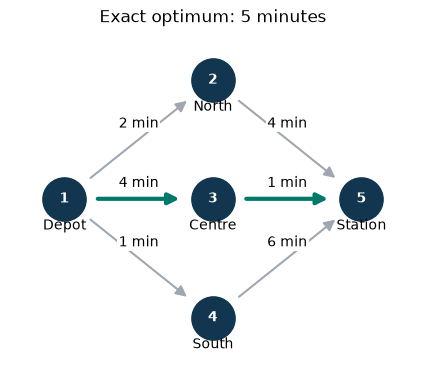

In [8]:
assert bqm.num_variables <= 20, "Exact enumeration is only for tiny models."
exact = dimod.ExactSolver().sample(bqm)
order = [list(exact.variables).index(i) for i in range(n_encoding)]
all_bits = np.asarray(exact.record.sample[:, order], dtype=int)
assert np.allclose(exact.record.energy, independent_energies(all_bits)), "QUBO/formula mismatch."

best_energy = float(exact.first.energy)
optimal_bits = all_bits[np.isclose(exact.record.energy, best_energy)]
for bits in optimal_bits:
    check = inspect_bits(bits)
    assert check["feasible"]
    assert np.isclose(check["minutes"], reference_optimum)
    assert np.isclose(best_energy, check["minutes"])
    assert generator.decode_bit_array(bits.tolist()) == [check["route"]]
assert np.isclose(best_energy, reference_optimum)

best_bits = [int(exact.first.sample[i]) for i in range(n_encoding)]
best_route = inspect_bits(best_bits)["route"]
assert np.isclose(float(generator.get_cost(best_bits)), best_energy)
print(f"Checked all {len(exact):,} bitstrings. Best route: {best_route}; {best_energy:g} minutes.")
print(f"Optimal bitstrings: {len(optimal_bits)}")
plot_route(best_route, title=f"Exact optimum: {best_energy:g} minutes")


For the supplied data, the routes through North, Centre and South take **6, 5 and
7 minutes**, respectively. The unique optimum is **1 → 3 → 5**, taking **5 minutes**.
Only three of the 32,768 bitstrings represent feasible routes.

The constant offset matters when interpreting energy: retaining it makes the
energy of a feasible route equal its travel time. Dropping it would preserve
the minimiser but change the reported energy.

This graph is deliberately easy to solve directly. Its purpose is to make every
stage inspectable, not to demonstrate a computational advantage. Exact bitstring
enumeration grows exponentially; do not carry it over to a large challenge model.


## 5. Solve with simulated annealing

Simulated annealing uses probabilistic updates and cooling to search for a low-energy
assignment. It is a classical heuristic and needs no quantum device.

We use dimod's reference implementation, suitable for this small teaching example.
It is slower than optimized samplers and should not be used for performance comparisons.
The exact solution from Section 4 provides an independent reference.

For every returned sample we check the one-hot structure, endpoints and graph edges.
We report the best feasible route, the fraction of feasible reads and the gap to
the exact optimum. Low energy alone does not establish feasibility.

A **read** is one annealing attempt. Each batch below contains 10 reads.
The helper sets a random seed for repeatability within the same environment.


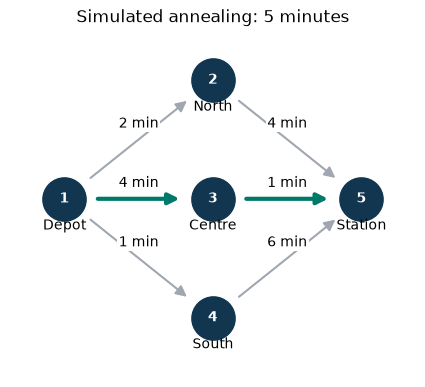

,solver,seed,seconds,best_route,best_minutes,gap_minutes,feasible_fraction,feasible_reads,total_reads
0,Simulated annealing,0,0.439932,"[1, 3, 5]",5.0,0.0,0.5,5,10


In [9]:
def summarise_samples(sampleset, solver_name, seconds, seed):
    total_reads = 0
    feasible_reads = 0
    best = None
    for datum in sampleset.data(fields=["sample", "energy", "num_occurrences"]):
        bits = [int(datum.sample[i]) for i in range(n_encoding)]
        result = inspect_bits(bits)
        total_reads += int(datum.num_occurrences)
        if result["feasible"]:
            feasible_reads += int(datum.num_occurrences)
            assert np.isclose(float(datum.energy), result["minutes"])
            assert generator.decode_bit_array(bits) == [result["route"]]
            if best is None or result["minutes"] < best["minutes"]:
                best = result
    return dict(solver=solver_name, seed=seed, seconds=seconds,
                best_route=best["route"] if best else None,
                best_minutes=best["minutes"] if best else np.nan,
                gap_minutes=best["minutes"] - reference_optimum if best else np.nan,
                feasible_fraction=feasible_reads / total_reads if total_reads else 0.0,
                feasible_reads=feasible_reads, total_reads=total_reads)

def sample_with_seed(sampler, bqm, seed, **settings):
    state = random.getstate()
    try:
        random.seed(seed)
        return sampler.sample(bqm, **settings)
    finally:
        random.setstate(state)

SOLVERS = {
    "Simulated annealing": (SimulatedAnnealingSampler(), dict(num_reads=10, num_sweeps=1000)),
}

first_runs = []
for name, (sampler, settings) in SOLVERS.items():
    started = time.perf_counter()
    sampleset = sample_with_seed(sampler, bqm, seed=0, **settings)
    elapsed = time.perf_counter() - started
    row = summarise_samples(sampleset, name, elapsed, seed=0)
    first_runs.append(row)
    if row["best_route"] is not None:
        plot_route(row["best_route"], title=f"{name}: {row['best_minutes']:g} minutes")
    else:
        print(f"{name}: no feasible route found. Inspect parameters and constraints.")

display(pd.DataFrame(first_runs))


## 6. Repeat the runs and interpret the results

Repeat simulated annealing with five seeds and inspect feasibility and optimality.
Elapsed time is recorded only to help judge the classroom runtime; this reference
implementation is not suitable for benchmarking solver performance.

We retain the tiny instance so that an exact reference remains available. Finding
the optimum on every run would be a useful check, not evidence of similar performance
on larger networks. A seed helps repeat runs within the same software environment;
results may differ across library or Python versions.


Read the result tables as follows:

- `best_minutes`: travel time of the best feasible route in a batch.
- `gap_minutes`: that travel time minus the exact optimum; zero is optimal.
- `feasible_fraction`: the fraction of individual reads that satisfy all constraints.
- `runs_with_optimum`: the number of batches containing at least one optimal route.

These measures answer different questions. A batch can contain an optimal route
even when some of its other reads are infeasible. Penalties make the global optimum
feasible for this model; they do not guarantee that every heuristic sample is feasible.


,solver,seed,seconds,best_route,best_minutes,gap_minutes,feasible_fraction,feasible_reads,total_reads,found_feasible,found_optimum
0,Simulated annealing,0,0.439932,"[1, 3, 5]",5.0,0.0,0.5,5,10,True,True
1,Simulated annealing,1,0.440191,"[1, 3, 5]",5.0,0.0,0.3,3,10,True,True
2,Simulated annealing,2,0.440029,"[1, 3, 5]",5.0,0.0,0.4,4,10,True,True
3,Simulated annealing,3,0.457355,"[1, 3, 5]",5.0,0.0,0.8,8,10,True,True
4,Simulated annealing,4,0.452431,"[1, 3, 5]",5.0,0.0,0.6,6,10,True,True


,runs,runs_with_feasible,runs_with_optimum,mean_feasible_fraction,median_best_minutes,median_seconds
solver,,,,,,
Simulated annealing,5,5,5,0.52,5.0,0.440191


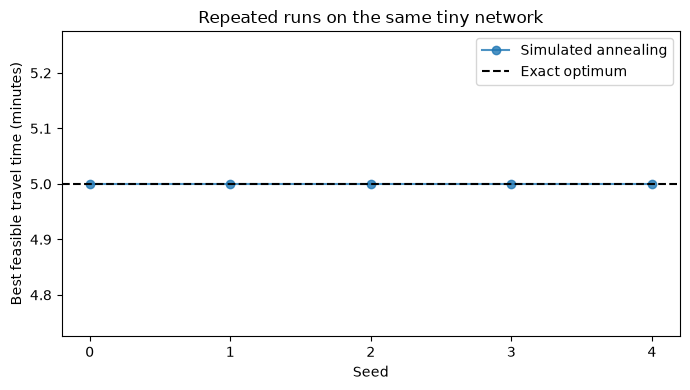

A missing point means no feasible route was found; check runs_with_feasible in the table.


In [10]:
rows = list(first_runs)
for seed in [1, 2, 3, 4]:
    for name, (sampler, settings) in SOLVERS.items():
        started = time.perf_counter()
        sampleset = sample_with_seed(sampler, bqm, seed=seed, **settings)
        elapsed = time.perf_counter() - started
        rows.append(summarise_samples(sampleset, name, elapsed, seed))

runs = pd.DataFrame(rows)
runs["found_feasible"] = runs.best_minutes.notna()
runs["found_optimum"] = np.isclose(runs.best_minutes, reference_optimum)
summary = runs.groupby("solver").agg(
    runs=("seed", "size"),
    runs_with_feasible=("found_feasible", "sum"),
    runs_with_optimum=("found_optimum", "sum"),
    mean_feasible_fraction=("feasible_fraction", "mean"),
    median_best_minutes=("best_minutes", "median"),
    median_seconds=("seconds", "median"),
)
display(runs)
display(summary)

fig, ax = plt.subplots(figsize=(7, 4))
for name, group in runs.groupby("solver"):
    ax.plot(group.seed, group.best_minutes, marker="o", label=name, alpha=0.8)
ax.axhline(reference_optimum, color="black", linestyle="--", label="Exact optimum")
ax.set(xlabel="Seed", ylabel="Best feasible travel time (minutes)",
       title="Repeated runs on the same tiny network")
ax.set_xticks([0, 1, 2, 3, 4])
ax.legend()
plt.tight_layout()
plt.show()
print("A missing point means no feasible route was found; check runs_with_feasible in the table.")


## 7. Try it yourself

Save a copy of this notebook. Start each exercise from the original network,
make one change at a time, and **restart and run all cells** so that the graph,
reference solution, penalty bound and QUBO remain consistent.

1. Change the time on edge `(1, 3)` from 4 to 7. Predict the new fastest route
   before running anything. Does simulated annealing find the new exact optimum?
2. Remove edge `(3, 5)`. Which routes remain feasible, and which is fastest? Why must a
   missing edge receive a penalty even though its entry in the adjacency matrix is zero?
3. Inspect one infeasible bitstring: an empty middle position or two selected
   vertices at the middle position. Which penalty terms reject it?
4. Try a smaller positive penalty by changing `PENALTY` before building the model.
   The feasibility assertion in the exact-check cell may fail: this is the result
   to investigate, not an assertion to delete. Explain what an infeasible minimiser gains.
5. Explain the difference between a route's travel time, its number of visited
   vertices and its QUBO energy. When are energy and travel time equal here?

**For your team's challenge:** decide how to extend this starting point to the
competing claims in the brief. Make your assumptions explicit and implement your
own capacity, timing and priority requirements. This notebook supplies the basic
workflow; it does not supply that allocation model.


**Record your findings:** for each change, write down your prediction, the exact
result, the annealing result and one sentence explaining any difference. The stated
route times in the worked example refer to the original data; after changing the
network, use the newly computed tables and plots.


## References

- [MQT ProblemSolver: Pathfinder guide](https://mqt.readthedocs.io/projects/problemsolver/en/stable/qubo_tools/pathfinder/index.html)
- [Pathfinder API](https://mqt.readthedocs.io/projects/problemsolver/en/stable/api/mqt/problemsolver/qubo_tools/pathfinder/index.html)
- [Version 0.5.0 source: constraint formulas](https://github.com/munich-quantum-toolkit/problemsolver/blob/v0.5.0/src/mqt/problemsolver/qubo_tools/pathfinder/cost_functions.py)
- [Version 0.5.0 source: QUBO matrix and constant handling](https://github.com/munich-quantum-toolkit/problemsolver/blob/v0.5.0/src/mqt/problemsolver/qubo_tools/qubo_generator.py)
- [Rovara, Quetschlich and Wille: A Framework to Formulate Pathfinding Problems for Quantum Computing](https://arxiv.org/abs/2404.10820)
- [dimod reference annealing sampler](https://docs.dwavequantum.com/en/latest/ocean/api_ref_dimod/generated/dimod.reference.samplers.SimulatedAnnealingSampler.sample.html)


